# Escalabilidade do tempo com o número de gerações
Verifica se o tempo de execução cresce linearmente com o número de gerações (32 a 2048), comparando a curva real com a reta que liga os extremos.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## 2. Dados e agregações (pandas)

In [2]:
CAMINHO_CSV = "../PythonCode/Outputs/results.csv"
N_CORES = 14

df = pd.read_csv(CAMINHO_CSV)
print("Formato:", df.shape)
display(df.head())

# Checagens básicas
contagem = df.groupby(["n_cores", "seed"]).size()
print("Repetições por par (n_cores, seed):", sorted(contagem.unique()))
print("Valores faltantes:", int(df.isna().sum().sum()))
print("Valores de n_cores:", sorted(df["n_cores"].unique()))
print("Seeds:", sorted(df["seed"].unique()))

# Colunas de tempo ordenadas pelo número de gerações
colunas_tempo = sorted(
    [c for c in df.columns if c.startswith("time_")],
    key=lambda c: int(c.split("_")[1]),
)

df_nc = df[df["n_cores"] == N_CORES]
assert len(df_nc) > 0, f"Nenhuma linha com n_cores == {N_CORES}"
print(f"\nLinhas com n_cores == {N_CORES}:", len(df_nc))

# 1) média das repetições dentro de cada seed
medias_por_seed = df_nc.groupby("seed")[colunas_tempo].mean()

# 2) média e desvio padrão (amostral) entre as seeds
tabela = pd.DataFrame({
    "tempo_medio": medias_por_seed.mean(),
    "desvio": medias_por_seed.std(ddof=1),
})
tabela.index = [int(c.split("_")[1]) for c in tabela.index]
tabela.index.name = "n_gens"

display(medias_por_seed)
display(tabela)


Formato: (75, 9)


,n_cores,seed,time_32_gen,time_64_gen,time_128_gen,time_256_gen,time_512_gen,time_1024_gen,time_2048_gen
0,1,4,43.053089,109.172627,261.788561,583.238489,1100.646439,2015.593947,3655.688589
1,1,4,43.275543,109.881091,262.925391,586.156081,1106.762622,2026.014179,3670.477950
2,1,4,42.944421,109.081151,261.657032,582.752661,1101.131244,2016.606922,3636.929797
3,2,4,23.378426,57.251122,137.759463,307.250374,580.691928,1062.958702,1928.137151
4,2,4,23.489738,58.209185,138.125194,306.061575,576.511741,1053.639430,1909.765799


Repetições por par (n_cores, seed): [np.int64(3)]
Valores faltantes: 0
Valores de n_cores: [np.int64(1), np.int64(2), np.int64(4), np.int64(8), np.int64(14)]
Seeds: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

Linhas com n_cores == 14: 15


,time_32_gen,time_64_gen,time_128_gen,time_256_gen,time_512_gen,time_1024_gen,time_2048_gen
seed,,,,,,,
0,8.577401,20.221825,45.447841,95.212077,197.468855,379.474678,678.208070
1,9.145970,20.204717,47.632620,100.378506,213.181679,407.511355,723.172564
2,10.757483,21.823763,44.588963,92.887158,188.032983,368.217700,729.741043
3,11.264704,24.486451,53.363576,106.748877,205.249778,383.826071,716.706285
4,13.716134,32.982168,77.615229,171.617403,322.937997,590.475472,1070.429519


,tempo_medio,desvio
n_gens,,
32,10.692339,2.021101
64,23.943785,5.345909
128,53.729646,13.783770
256,113.368804,32.994829
512,225.374258,55.329511
1024,425.901055,93.107467
2048,783.651496,161.559316


## 3. Conversão para numpy, reta de referência e gráficos

In [3]:
gens = tabela.index.to_numpy(dtype=float)
tempo = tabela["tempo_medio"].to_numpy()
desvio = tabela["desvio"].to_numpy()

# Reta de referência ligando os extremos (32 e 2048 gerações)
reta = tempo[0] + (tempo[-1] - tempo[0]) * (gens - gens[0]) / (gens[-1] - gens[0])

# Resíduos: positivo = real acima da reta; negativo = real abaixo
residuo_s = tempo - reta
residuo_pct = residuo_s / tempo * 100
erro_pct = desvio / tempo * 100   # variação entre seeds em % do tempo real

print(f"{'gens':>6} {'tempo (s)':>12} {'reta (s)':>12} {'resíduo (s)':>13} {'resíduo (%)':>12}")
for g, t, r, rs, rp in zip(gens, tempo, reta, residuo_s, residuo_pct):
    print(f"{g:6.0f} {t:12.2f} {r:12.2f} {rs:13.2f} {rp:12.2f}")


  gens    tempo (s)     reta (s)   resíduo (s)  resíduo (%)
    32        10.69        10.69          0.00         0.00
    64        23.94        22.96          0.98         4.10
   128        53.73        47.50          6.23        11.59
   256       113.37        96.58         16.79        14.81
   512       225.37       194.73         30.64        13.60
  1024       425.90       391.04         34.86         8.19
  2048       783.65       783.65          0.00         0.00


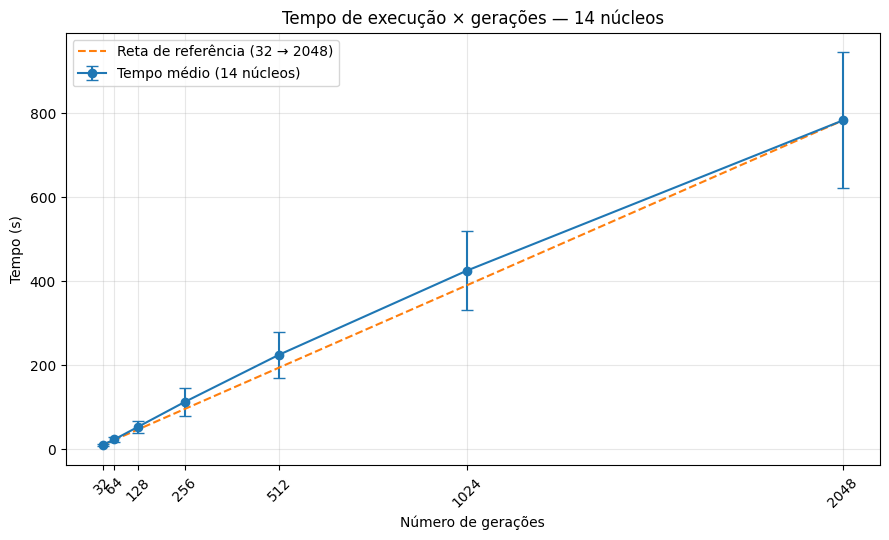

In [4]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.errorbar(gens, tempo, yerr=desvio, fmt="o-", capsize=4, label=f"Tempo médio ({N_CORES} núcleos)")
ax.plot(gens, reta, "--", label="Reta de referência (32 → 2048)")
ax.set_xlabel("Número de gerações")
ax.set_ylabel("Tempo (s)")
ax.set_title(f"Tempo de execução × gerações — {N_CORES} núcleos")
ax.set_xticks(gens)
ax.tick_params(axis="x", rotation=45)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()


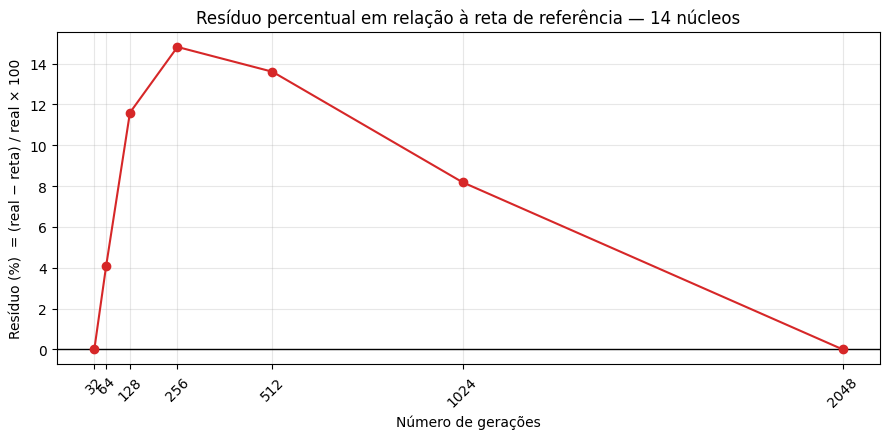

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.errorbar(gens, residuo_pct, fmt="o-", capsize=4, color="tab:red")
ax.axhline(0, color="black", linewidth=1)
ax.set_xlabel("Número de gerações")
ax.set_ylabel("Resíduo (%)  = (real − reta) / real × 100")
ax.set_title(f"Resíduo percentual em relação à reta de referência — {N_CORES} núcleos")
ax.set_xticks(gens)
ax.tick_params(axis="x", rotation=45)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()


